In [1]:
#Load the dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv("bank-additional-full-1 (1).csv",sep=';')

In [5]:
data.head(7)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45.0,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59.0,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [6]:
# check the info about dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41199 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41195 non-null  float64
 1   job             41194 non-null  object 
 2   marital         41194 non-null  object 
 3   education       41194 non-null  object 
 4   default         41195 non-null  object 
 5   housing         41196 non-null  object 
 6   loan            41195 non-null  object 
 7   contact         41195 non-null  object 
 8   month           41196 non-null  object 
 9   day_of_week     41196 non-null  object 
 10  duration        41196 non-null  float64
 11  campaign        41196 non-null  float64
 12  pdays           41196 non-null  float64
 13  previous        41196 non-null  float64
 14  poutcome        41194 non-null  object 
 15  emp.var.rate    41196 non-null  float64
 16  cons.price.idx  41195 non-null  float64
 17  cons.conf.idx   41196 non-null 

In [7]:
# check for duplicate values
data.duplicated().sum()

np.int64(15)

In [8]:
# check for rows and columns in dataset
data.shape

(41199, 21)

In [10]:
# check datatypes for each column?
data.dtypes

age               float64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration          float64
campaign          float64
pdays             float64
previous          float64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

In [11]:
# removing null values-
data.dropna(inplace=True)

In [12]:
data.isnull().sum().sum()

np.int64(0)

In [13]:
# remove the duplicate values
data.drop_duplicates(inplace=True)

In [14]:
data.duplicated().sum()

np.int64(0)

In [16]:
# statistical summary of data
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000
mean,40.025111,258.315346,2.567890,962.465697,0.173033,0.081893,93.575749,-40.503113,3.621230,5167.029929
std,10.423948,259.302190,2.770286,186.934918,0.494975,1.570874,0.578862,4.628082,1.734463,72.257442
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.000000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [17]:
#Boxplot - for checking outliers

#using boxplot we will be visualizing the outliers, after that we will be using IQR method and handle the outliers.

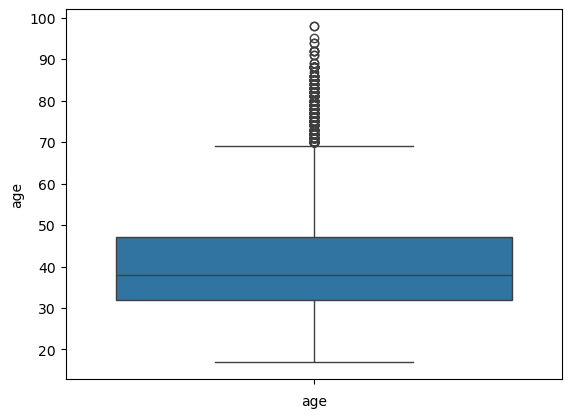

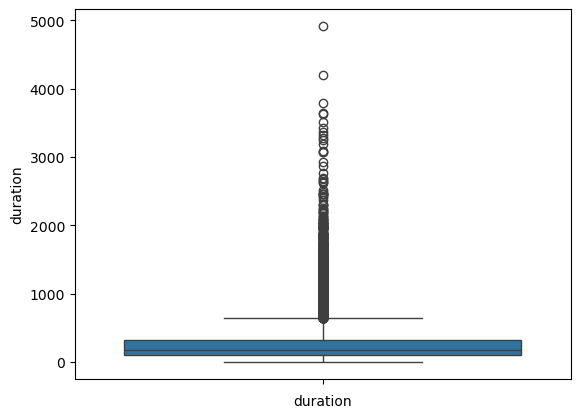

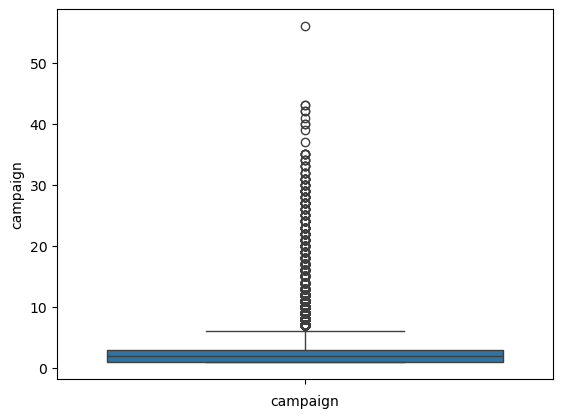

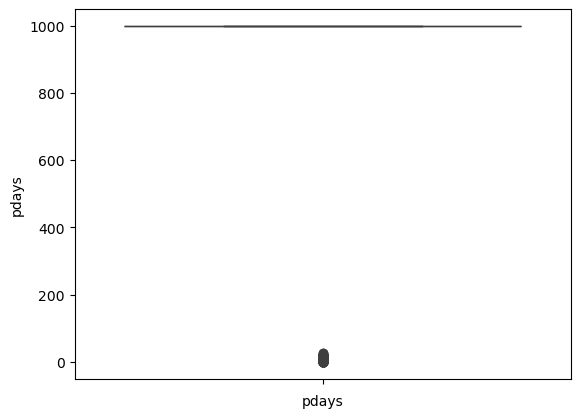

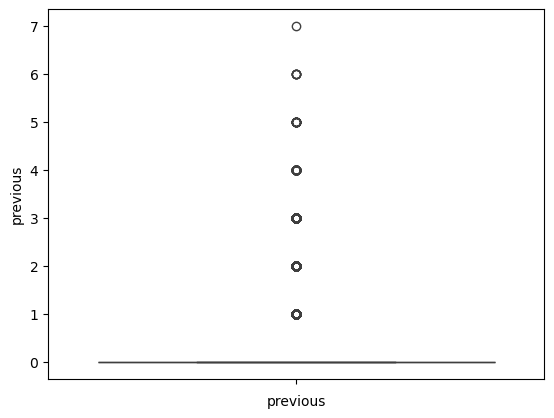

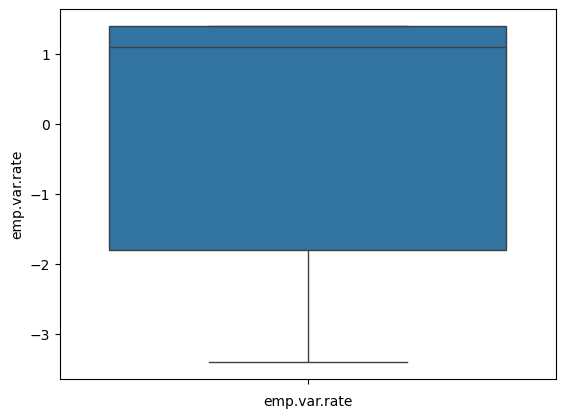

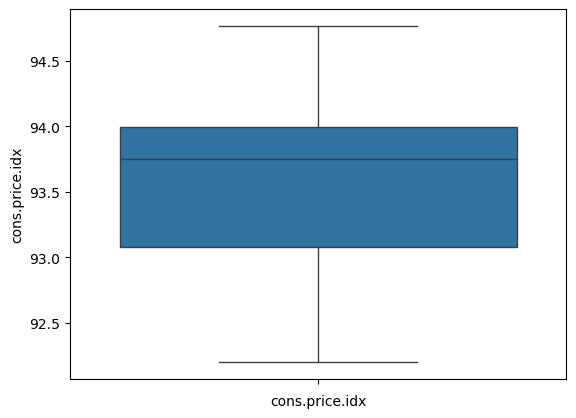

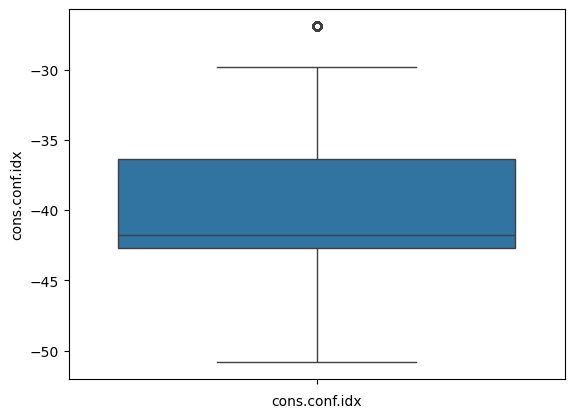

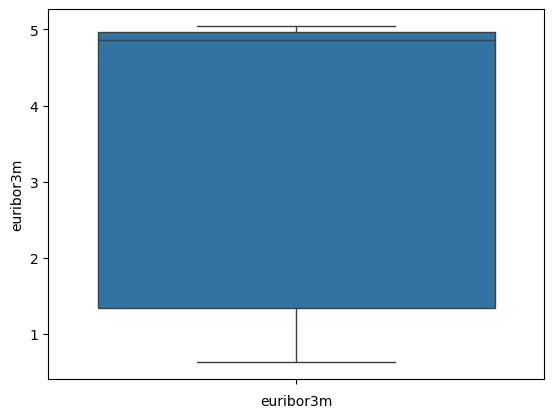

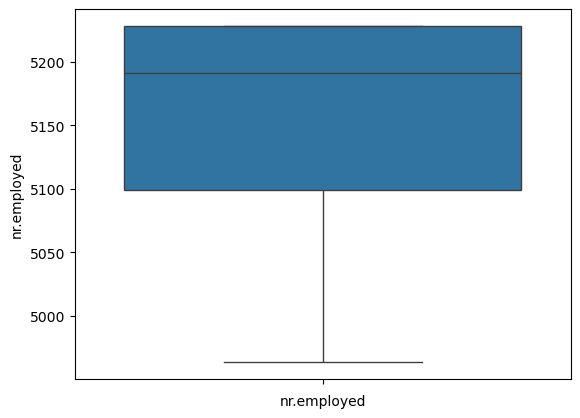

In [18]:
for i in data.columns:
  if(data[i].dtype!='object'):
    sns.boxplot(data[i])
    plt.xlabel(i)
    plt.show()

In [19]:

#with the reference of the above boxplot we can observe that some columns have outliers:

#1- age - there are outliers

#2- duration - there are outliers

#3- campaign - there are outliers

#4- pdays - there are no outliers - no box

#5- previous - there are no outliers - no box

#6- emp.var.rate - there are no outliers

#7- cons.price.idx - there are no outliers

#8- cons.conf.idx - there are outliers

#9- nr.employed - there are no outliers

In [21]:
#IQR method (Remove outliers)

out_list = ['age','campaign','cons.conf.idx']
for col in out_list:
  q1 = data[col].quantile(0.25)
  q3 = data[col].quantile(0.75)

  iqr = q3 - q1
  lb = q1 - 1.5 * iqr
  ub = q3 + 1.5 * iqr

In [23]:
lb

np.float64(-52.150000000000006)

In [24]:
ub

np.float64(-26.949999999999992)

In [25]:
data = data[(data[col]<=ub) & (data[col]>=lb)]

In [26]:
data['duration'].value_counts()

duration
90.0      169
85.0      169
136.0     166
73.0      163
124.0     162
         ... 
3785.0      1
2035.0      1
1407.0      1
1563.0      1
1267.0      1
Name: count, Length: 1540, dtype: int64

In [27]:
data['y']

0         no
1         no
2         no
3         no
4         no
        ... 
41184     no
41185     no
41186    yes
41187     no
41193     no
Name: y, Length: 40731, dtype: object

In [28]:
# convert the value of target column from yes no to 0 - 1
data['y'] = np.where(data['y']=='yes',1,0)

C:\Users\Admin\AppData\Local\Temp\ipykernel_16060\2905454572.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['y'] = np.where(data['y']=='yes',1,0)


In [29]:
data['y'].unique()

array([0, 1])

In [30]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40731 entries, 0 to 41193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             40731 non-null  float64
 1   job             40731 non-null  object 
 2   marital         40731 non-null  object 
 3   education       40731 non-null  object 
 4   default         40731 non-null  object 
 5   housing         40731 non-null  object 
 6   loan            40731 non-null  object 
 7   contact         40731 non-null  object 
 8   month           40731 non-null  object 
 9   day_of_week     40731 non-null  object 
 10  duration        40731 non-null  float64
 11  campaign        40731 non-null  float64
 12  pdays           40731 non-null  float64
 13  previous        40731 non-null  float64
 14  poutcome        40731 non-null  object 
 15  emp.var.rate    40731 non-null  float64
 16  cons.price.idx  40731 non-null  float64
 17  cons.conf.idx   40731 non-null  floa

In [31]:
#What is Encoding?

#In machine learning models works only with numeric data . But we have object data type here. 
#So we need to convert text data to numbers . The process of converting text to numbers is known as encoding.

In [ ]:
#Label Encoding- used when we have 2 categories or data is in order.

#- how it works

#- 1- find unique values

#- 2- sort them alphabetically

#- 3- assign numbers starting from 0

In [32]:
from sklearn.preprocessing import LabelEncoder

In [33]:
le = LabelEncoder()
for i in data.columns:
  if  data[i].dtype == 'object':
    data[i] = le.fit_transform(data[i])

C:\Users\Admin\AppData\Local\Temp\ipykernel_16060\1122475491.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[i] = le.fit_transform(data[i])
C:\Users\Admin\AppData\Local\Temp\ipykernel_16060\1122475491.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[i] = le.fit_transform(data[i])
C:\Users\Admin\AppData\Local\Temp\ipykernel_16060\1122475491.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40731 entries, 0 to 41193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             40731 non-null  float64
 1   job             40731 non-null  int64  
 2   marital         40731 non-null  int64  
 3   education       40731 non-null  int64  
 4   default         40731 non-null  int64  
 5   housing         40731 non-null  int64  
 6   loan            40731 non-null  int64  
 7   contact         40731 non-null  int64  
 8   month           40731 non-null  int64  
 9   day_of_week     40731 non-null  int64  
 10  duration        40731 non-null  float64
 11  campaign        40731 non-null  float64
 12  pdays           40731 non-null  float64
 13  previous        40731 non-null  float64
 14  poutcome        40731 non-null  int64  
 15  emp.var.rate    40731 non-null  float64
 16  cons.price.idx  40731 non-null  float64
 17  cons.conf.idx   40731 non-null  floa

In [35]:
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,3,1,0,0,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0,0
1,57.0,7,1,3,1,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0,0
2,37.0,7,1,3,0,2,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0,0
3,40.0,0,1,1,0,0,0,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0,0
4,56.0,7,1,3,0,0,2,1,6,1,...,1.0,999.0,0.0,1,1.1,93.994,-36.4,4.857,5191.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41184,46.0,1,1,5,0,0,0,0,7,0,...,1.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6,0
41185,56.0,5,1,6,0,2,0,0,7,0,...,2.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6,0
41186,44.0,9,1,5,0,0,0,0,7,0,...,1.0,999.0,0.0,1,-1.1,94.767,-50.8,1.028,4963.6,1
41187,74.0,5,1,5,0,2,0,0,7,0,...,3.0,999.0,1.0,0,-1.1,94.767,-50.8,1.028,4963.6,0


In [36]:
# correlation
corr_mat = data.corr()
corr_mat

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,-0.001080,-0.389483,-0.113874,0.168933,-0.001415,-0.006268,0.010280,-0.035488,-0.020458,...,0.006891,-0.031447,0.020875,0.019587,0.013249,0.013382,0.119106,0.021089,-0.006043,0.027371
job,-0.001080,1.000000,0.028532,0.136926,-0.027757,0.007493,-0.010814,-0.023993,-0.036882,-0.000664,...,-0.006116,-0.027600,0.020893,0.010910,-0.004289,-0.012608,0.049746,-0.004911,-0.016206,0.022704
marital,-0.389483,0.028532,1.000000,0.108082,-0.079047,0.010992,0.005749,-0.054690,-0.009853,0.003818,...,-0.006743,-0.039342,0.038886,0.003323,-0.084098,-0.056490,-0.039592,-0.091668,-0.086010,0.044565
education,-0.113874,0.136926,0.108082,1.000000,-0.187683,0.016661,0.006095,-0.106699,-0.085887,-0.018755,...,0.000883,-0.048222,0.039057,0.018948,-0.043235,-0.082032,0.080601,-0.035678,-0.040926,0.058175
default,0.168933,-0.027757,-0.079047,-0.187683,1.000000,-0.015994,-0.004444,0.133744,-0.008073,-0.007850,...,0.031121,0.079370,-0.100769,0.022793,0.198331,0.162300,0.042915,0.190582,0.184587,-0.097546
housing,-0.001415,0.007493,0.010992,0.016661,-0.015994,1.000000,0.044498,-0.083429,-0.018552,0.002590,...,-0.011351,-0.009982,0.022857,-0.013684,-0.062064,-0.082555,-0.035931,-0.060398,-0.047113,0.012387
loan,-0.006268,-0.010814,0.005749,0.006095,-0.004444,0.044498,1.000000,-0.009023,-0.004398,-0.009454,...,0.004832,-0.001209,-0.000363,-0.001295,-0.000116,-0.004359,-0.009900,-0.001355,0.002172,-0.003391
contact,0.010280,-0.023993,-0.054690,-0.106699,0.133744,-0.083429,-0.009023,1.000000,0.290682,-0.009498,...,0.075450,0.116009,-0.211589,0.120794,0.393903,0.595934,0.282365,0.398465,0.265342,-0.141610
month,-0.035488,-0.036882,-0.009853,-0.085887,-0.008073,-0.018552,-0.004398,0.290682,1.000000,0.027120,...,-0.056299,-0.036874,0.093939,-0.066213,-0.145333,0.032212,-0.045645,-0.090332,-0.191895,-0.023174
day_of_week,-0.020458,-0.000664,0.003818,-0.018755,-0.007850,0.002590,-0.009454,-0.009498,0.027120,1.000000,...,-0.037887,-0.009318,-0.004625,0.018550,0.035913,0.007076,0.041804,0.041028,0.030738,0.016350


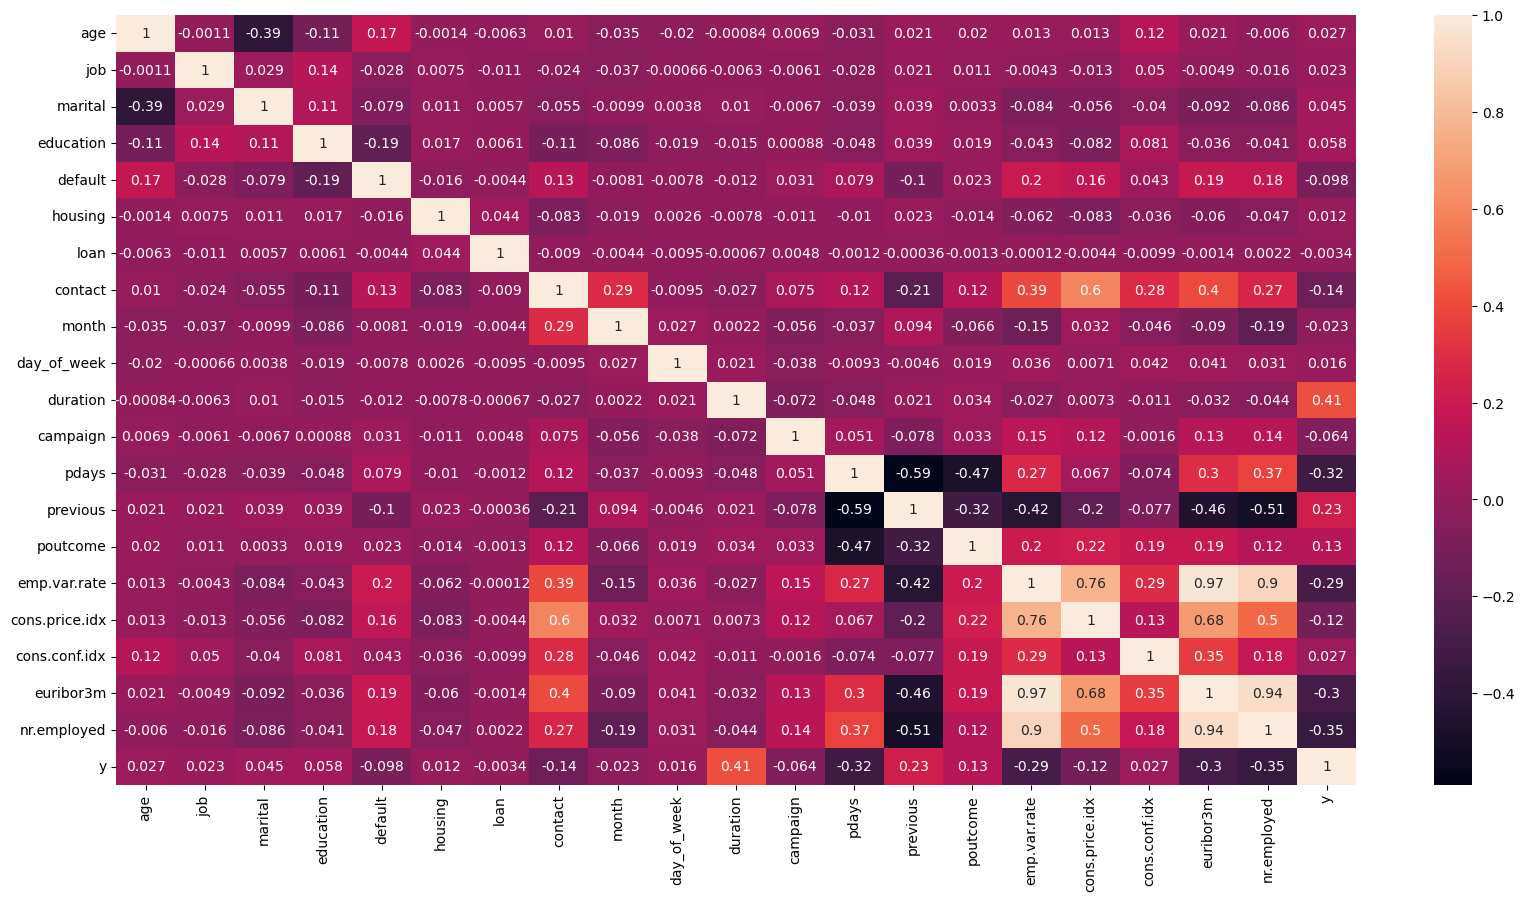

In [37]:
# visualize the correlation?
plt.figure(figsize=(20,10))
sns.heatmap(corr_mat , annot=True)
plt.show()

**feature selection**


**VIF (Variance Inflation Factor)** - It is a feature selection technique  which calculates the multicollinearity between columns and drops the column with the  highest values.

- It removes the multicollinearity from data

- **Multicollinearity-** Two or more input features are giving almost the same information

- Features are too strongly related to each other

- **VIF value** (HOW TO INTERPRET?)

- 1 --------> no multicollinearity

- 1-5 --------> Low (ok)

- (greater than  5) ---------> severe

In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [39]:
  # create an empty list
  col_list = []
  for i in data.columns:
    if ((data[i].dtype!='object') & (i!='y')):
      col_list.append(i)


  X = data[col_list]
  vif_data = pd.DataFrame()
  vif_data['Column_name'] = X.columns
  vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]

In [40]:
vif_data

,Column_name,VIF_score
0,age,20.000026
1,job,2.116836
2,marital,5.640953
3,education,4.471495
4,default,1.406251
5,housing,2.206095
6,loan,1.208298
7,contact,2.888792
8,month,6.659115
9,day_of_week,3.082905


In [41]:
data = data.drop(['nr.employed'],axis=1)

In [42]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [43]:
vif_data

,Column_name,VIF_score
0,age,19.948544
1,job,2.116614
2,marital,5.639827
3,education,4.470836
4,default,1.402993
5,housing,2.205679
6,loan,1.208235
7,contact,2.426418
8,month,5.714330
9,day_of_week,3.082510


In [44]:
data = data.drop(['cons.price.idx'],axis=1)

In [45]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [46]:
vif_data


,Column_name,VIF_score
0,age,18.770550
1,job,2.110914
2,marital,5.495443
3,education,4.420257
4,default,1.402979
5,housing,2.204181
6,loan,1.207823
7,contact,2.336361
8,month,5.665847
9,day_of_week,3.067854


In [47]:
data = data.drop(['pdays'],axis=1)

In [49]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]

In [50]:
vif_data

,Column_name,VIF_score
0,age,17.787693
1,job,2.107574
2,marital,5.376501
3,education,4.368674
4,default,1.402962
5,housing,2.201098
6,loan,1.207747
7,contact,2.272505
8,month,5.617107
9,day_of_week,3.056453


In [51]:
data = data.drop(['euribor3m'],axis=1)

In [52]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [53]:
vif_data

,Column_name,VIF_score
0,age,15.273710
1,job,2.101736
2,marital,5.185168
3,education,4.203819
4,default,1.402802
5,housing,2.193281
6,loan,1.207369
7,contact,2.262052
8,month,5.241473
9,day_of_week,3.018466


In [54]:
data = data.drop(['cons.conf.idx'],axis=1)

In [55]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [56]:
vif_data

,Column_name,VIF_score
0,age,9.839499
1,job,2.093525
2,marital,4.264339
3,education,4.065843
4,default,1.400548
5,housing,2.153565
6,loan,1.203693
7,contact,2.239610
8,month,4.783782
9,day_of_week,2.949474


In [57]:
data = data.drop(['age'],axis=1)

In [58]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [59]:
vif_data



,Column_name,VIF_score
0,job,2.060950
1,marital,4.250289
2,education,3.903981
3,default,1.319667
4,housing,2.100017
5,loan,1.200025
6,contact,2.237971
7,month,4.510831
8,day_of_week,2.852789
9,duration,1.938318


In [60]:
data = data.drop(['poutcome'],axis=1)

In [61]:
col_list = []
for i in data.columns:
  if ((data[i].dtype!='object') & (i!='y')):
    col_list.append(i)


X = data[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]

In [62]:
vif_data

,Column_name,VIF_score
0,job,2.033830
1,marital,3.986173
2,education,3.639115
3,default,1.305687
4,housing,2.058340
5,loan,1.196985
6,contact,2.221511
7,month,4.334887
8,day_of_week,2.741568
9,duration,1.879325


**Model Building**

In [63]:
X

,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous,emp.var.rate
0,3,1,0,0,0,0,1,6,1,261.0,1.0,0.0,1.1
1,7,1,3,1,0,0,1,6,1,149.0,1.0,0.0,1.1
2,7,1,3,0,2,0,1,6,1,226.0,1.0,0.0,1.1
3,0,1,1,0,0,0,1,6,1,151.0,1.0,0.0,1.1
4,7,1,3,0,0,2,1,6,1,307.0,1.0,0.0,1.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
41184,1,1,5,0,0,0,0,7,0,383.0,1.0,0.0,-1.1
41185,5,1,6,0,2,0,0,7,0,189.0,2.0,0.0,-1.1
41186,9,1,5,0,0,0,0,7,0,442.0,1.0,0.0,-1.1
41187,5,1,5,0,2,0,0,7,0,239.0,3.0,1.0,-1.1


In [65]:
y = data['y']
y

0        0
1        0
2        0
3        0
4        0
        ..
41184    0
41185    0
41186    1
41187    0
41193    0
Name: y, Length: 40731, dtype: int64

In [66]:
from sklearn.model_selection import train_test_split

In [67]:
x_train , x_test , y_train , y_test = train_test_split(X,y,test_size=0.20 , random_state = 42)

In [68]:
x_train

,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous,emp.var.rate
36969,9,1,6,1,2,0,0,3,2,160.0,1.0,0.0,-2.9
13206,7,2,3,0,2,0,0,3,4,85.0,1.0,0.0,1.4
36178,1,1,0,0,0,2,0,6,4,74.0,2.0,0.0,-1.8
34184,0,2,6,0,2,0,1,6,4,51.0,3.0,0.0,-1.8
2347,0,1,6,0,0,0,1,6,3,174.0,1.0,0.0,1.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6266,1,1,2,0,0,2,1,6,3,100.0,2.0,0.0,1.1
11285,0,1,2,0,2,0,1,4,2,120.0,1.0,0.0,1.4
38616,3,1,0,0,2,0,0,7,1,173.0,1.0,0.0,-3.4
860,4,1,6,0,2,0,1,6,4,295.0,2.0,0.0,1.1


In [69]:
y_train

36969    0
13206    0
36178    0
34184    0
2347     0
        ..
6266     0
11285    0
38616    0
860      0
15798    0
Name: y, Length: 32584, dtype: int64

In [70]:
x_test

,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous,emp.var.rate
18897,9,0,5,0,0,2,0,1,1,68.0,1.0,0.0,1.4
13317,1,1,1,1,0,0,0,3,4,91.0,1.0,0.0,1.4
36223,9,2,6,0,0,0,0,6,2,68.0,1.0,0.0,-1.8
22626,9,0,3,0,2,0,0,1,0,291.0,3.0,0.0,1.4
27966,0,1,3,1,2,0,0,5,3,310.0,1.0,0.0,-1.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
41119,1,2,1,0,2,0,0,7,3,330.0,1.0,0.0,-1.1
37318,5,1,3,0,2,0,0,1,3,151.0,1.0,0.0,-2.9
10960,7,1,2,0,2,0,1,4,4,324.0,2.0,0.0,1.4
7,1,1,7,1,0,0,1,6,1,217.0,1.0,0.0,1.1


In [71]:
y_test

18897    0
13317    0
36223    0
22626    0
27966    0
        ..
41119    1
37318    0
10960    0
7        0
18890    0
Name: y, Length: 8147, dtype: int64

In [72]:
from sklearn.linear_model import LogisticRegression

In [73]:
model = LogisticRegression()

In [74]:
model.fit(x_train,y_train)   # training the model

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [75]:
y_pred = model.predict(x_test)

In [76]:
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [77]:
from sklearn.metrics import*

In [78]:
accuracy_score(y_test , y_pred)*100

89.71400515527188

In [ ]:
Dataset link :- https://drive.google.com/file/d/19O3hzFSf5Rr2QCO-Kn0lpUoZrDRnGbUD/view